# AlphaEvolve + **SmolVLM2-2.2B-Instruct** on **ChartQA** — Google Colab

Runs **AlphaEvolve** (`evolve_chartqa.py`) on **HuggingFaceM4/ChartQA val** with backbone **`HuggingFaceTB/SmolVLM2-2.2B-Instruct`** (override via `VLM_HF_ID`).

**GPU:** T4-friendly small-footprint VLM from Hugging Face.

**Colab:** **Runtime → GPU**. **Secrets:** `HF_TOKEN`, `GEMINI_API_KEY`.

**Project path:** `/content/evolving-vlm-325/evolving-vlm-inference-main` (upload or `GIT_REPO_URL`).


In [ ]:
import os
from pathlib import Path

PROJECT_ROOT = Path(os.environ.get("COLAB_PROJECT_ROOT", "/content/evolving-vlm-325/evolving-vlm-inference-main"))
GIT_REPO_URL = os.environ.get("GIT_REPO_URL", "")

VLM_SLUG = "smolvlm2"
VLM_HF_ID = os.environ.get("VLM_HF_ID", "HuggingFaceTB/SmolVLM2-2.2B-Instruct")
os.environ["VLM_HF_ID"] = VLM_HF_ID

NUM_GENERATIONS = int(os.environ.get("NUM_GENERATIONS", "3"))
POPULATION_SIZE = int(os.environ.get("POPULATION_SIZE", "6"))

print("PROJECT_ROOT:", PROJECT_ROOT)
print("VLM:", VLM_HF_ID, f"({VLM_SLUG})")
print("NUM_GENERATIONS:", NUM_GENERATIONS, "POPULATION_SIZE:", POPULATION_SIZE)
print("GPU note:", 'T4-friendly small-footprint VLM from Hugging Face.')



PROJECT_ROOT: /content/evolving-vlm-325/evolving-vlm-inference-main
VLM: HuggingFaceTB/SmolVLM2-2.2B-Instruct (smolvlm2)
NUM_GENERATIONS: 3 POPULATION_SIZE: 6
GPU note: T4-friendly small-footprint VLM from Hugging Face.


In [ ]:
import zipfile
from pathlib import Path

zip_path = Path("/content/projectFiles.zip")  # change if your file name differs
out_dir = Path("/content")

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(out_dir)

# If the zip already contains a top-level folder "evolving-vlm-inference-main", you're done.
# If it extracted into a wrong name, rename so this path exists:
assert (out_dir / "evolving-vlm-325/evolving-vlm-inference-main").is_dir(), list(out_dir.iterdir())



In [ ]:
%%capture
!pip install -q "transformers>=4.48.0" num2words torch torchvision pillow accelerate google-generativeai bitsandbytes datasets huggingface_hub



In [ ]:
import torch
if not torch.cuda.is_available():
    raise RuntimeError(
        "No GPU. In Colab: Runtime → Change runtime type → GPU (e.g. T4), then re-run."
    )
print("GPU:", torch.cuda.get_device_name(0))



GPU: NVIDIA A100-SXM4-40GB


In [ ]:
import os, shutil, subprocess
from pathlib import Path

if GIT_REPO_URL:
    if PROJECT_ROOT.exists():
        shutil.rmtree(PROJECT_ROOT)
    subprocess.run(["git", "clone", "--depth", "1", GIT_REPO_URL, str(PROJECT_ROOT)], check=True)
elif not PROJECT_ROOT.exists():
    raise FileNotFoundError(
        f"{PROJECT_ROOT} not found. Upload repo to /content/evolving-vlm-325/evolving-vlm-inference-main or set GIT_REPO_URL."
    )

os.chdir(PROJECT_ROOT)
print("cwd:", os.getcwd())



cwd: /content/evolving-vlm-325/evolving-vlm-inference-main


In [ ]:
import os
import re
import shutil
from pathlib import Path

os.environ["VLM_HF_ID"] = VLM_HF_ID
_src = PROJECT_ROOT / "seeds" / "seed_smolvlm2.py"
_dst = PROJECT_ROOT / "seed_instruct.py"
if not _src.is_file():
    raise FileNotFoundError(f"Missing seed: {_src} — upload the full repo or re-run tools/restore_colab_notebooks.py")
text = _src.read_text(encoding="utf-8")
text = re.sub(r'_DEFAULT_MODEL = "[^"]+"', f'_DEFAULT_MODEL = "{VLM_HF_ID}"', text, count=1)
_dst.write_text(text, encoding="utf-8")
print("Deployed", _dst, "for", VLM_HF_ID)



Deployed /content/evolving-vlm-325/evolving-vlm-inference-main/seed_instruct.py for HuggingFaceTB/SmolVLM2-2.2B-Instruct


In [ ]:
# Optional: upload evolve_chartqa.py / evolved_chartqa.py into PROJECT_ROOT (Colab sidebar).
print("Optional: upload evolve_chartqa.py or evolved_chartqa.py into", PROJECT_ROOT)



Optional: upload evolve_chartqa.py or evolved_chartqa.py into /content/evolving-vlm-325/evolving-vlm-inference-main


In [ ]:
# import os
# from google.colab import userdata

# try:
#     os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
# except Exception:
#     from huggingface_hub import login
#     login()

# try:
#     os.environ["GEMINI_API_KEY"] = userdata.get("GEMINI_API_KEY")
# except Exception:
#     pass

# if not os.environ.get("GEMINI_API_KEY"):
#     from getpass import getpass
#     os.environ["GEMINI_API_KEY"] = getpass("Enter GEMINI_API_KEY: ")

# assert os.environ.get("GEMINI_API_KEY"), "GEMINI_API_KEY is required."
import os
from google.colab import userdata
from huggingface_hub import login

# ---------- HF TOKEN ----------
try:
    hf_token = userdata.get("HF_TOKEN")
    os.environ["HF_TOKEN"] = hf_token
    login(token=hf_token)
    print("HF login successful")
except Exception:
    print("HF_TOKEN not found in Colab secrets")

# ---------- GEMINI API ----------
try:
    os.environ["GEMINI_API_KEY"] = userdata.get("GEMINI_API_KEY")
except Exception:
    pass

if not os.environ.get("GEMINI_API_KEY"):
    from getpass import getpass
    os.environ["GEMINI_API_KEY"] = getpass("Enter GEMINI_API_KEY: ")

assert os.environ.get("GEMINI_API_KEY"), "GEMINI_API_KEY is required."



Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


HF login successful


In [ ]:
import os
import sys
import importlib.util
from pathlib import Path

os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))


def load_module(name: str, path: Path):
    spec = importlib.util.spec_from_file_location(name, path)
    m = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(m)
    return m


from datasets import load_dataset

_sample_dir = Path("/tmp/chartqa_colab_sample")
_sample_dir.mkdir(parents=True, exist_ok=True)
_ds = load_dataset("HuggingFaceM4/ChartQA", split="val")
_row = _ds[0]
_img = _row["image"]
_p = _sample_dir / "sample0.png"
if hasattr(_img, "convert"):
    _img.convert("RGB").save(_p)
_lab = _row.get("label")
_gold = str(_lab[0]) if isinstance(_lab, (list, tuple)) and _lab else str(_lab)
SAMPLE = {"image_path": str(_p), "question": _row["query"], "qid": None, "gold": _gold}
print("Sample:", SAMPLE["question"][:120], "Gold:", SAMPLE["gold"])



README.md:   0%|          | 0.00/852 [00:00<?, ?B/s]

data/train-00000-of-00003-49492f364babfa(…):   0%|          | 0.00/219M [00:00<?, ?B/s]

data/train-00001-of-00003-7302bae5e425bb(…):   0%|          | 0.00/311M [00:00<?, ?B/s]

data/train-00002-of-00003-194c9400785577(…):   0%|          | 0.00/315M [00:00<?, ?B/s]

data/val-00000-of-00001-0f11003c77497969(…):   0%|          | 0.00/50.2M [00:00<?, ?B/s]

data/test-00000-of-00001-e2cd0b7a0f9eb20(…):   0%|          | 0.00/68.9M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/28299 [00:00<?, ? examples/s]

Generating val split:   0%|          | 0/1920 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2500 [00:00<?, ? examples/s]

Sample: What's the color of graph with 56 as the highest value? Gold: Blue


In [ ]:
initial = load_module("alphaevolve_seed_colab", PROJECT_ROOT / "seed_instruct.py")
before_pred = initial.vlm_inference(SAMPLE["image_path"], SAMPLE["question"], SAMPLE["qid"])
print("=== EXAMPLE — generation 0 (SmolVLM2-2.2B-Instruct / ChartQA) ===")
print("Prediction:", before_pred)
print("Gold      :", SAMPLE["gold"])


config.json: 0.00B [00:00, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/657 [00:00<?, ?it/s]

...

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

added_tokens.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/868 [00:00<?, ?B/s]

=== EXAMPLE — generation 0 (SmolVLM2-2.2B-Instruct / ChartQA) ===
Prediction:  Blue.
Gold      : Blue


In [ ]:
from evaluate_chartqa import evaluate

print("=== BENCHMARK — generation 0 ===")
bench_before = evaluate(initial, return_details=False)
for k in ("desc_accuracy", "num_desc_evaluated", "num_errors", "total_time", "avg_time_per_query"):
    print(f"  {k}: {bench_before[k]}")


=== BENCHMARK — generation 0 ===
  desc_accuracy: 0.11458333333333333
  num_desc_evaluated: 192
  num_errors: 0
  total_time: 108.47910213470459
  avg_time_per_query: 0.5649953236182531


In [ ]:
import gc, sys, torch
_mname = "alphaevolve_seed_colab"
if _mname in sys.modules:
    mod = sys.modules.pop(_mname)
    for attr in ("_model", "_processor"):
        if hasattr(mod, attr):
            setattr(mod, attr, None)
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
print("Released generation-0 module.")


Released generation-0 module.


In [ ]:
import evolve_chartqa

evolve_chartqa.EXPECTED_MODEL_NAME = VLM_HF_ID
evolve_chartqa.NUM_GENERATIONS = NUM_GENERATIONS
evolve_chartqa.POPULATION_SIZE = POPULATION_SIZE
population, history = evolve_chartqa.run_evolution()
print("History entries:", len(history))


/usr/local/lib/python3.12/dist-packages/google/colab/_import_hooks/_hook_injector.py:55: FutureWarning: 

All support for the `google.generativeai` package has ended. It will no longer be receiving 
updates or bug fixes. Please switch to the `google.genai` package as soon as possible.
See README for more details:

https://github.com/google-gemini/deprecated-generative-ai-python/blob/main/README.md

  loader.exec_module(module)


Generations : 25  |  Population : 10
Gemini model: gemini-2.5-flash  (override with GEMINI_MODEL env; 2.0-flash is unavailable for new keys)
Train split : 102 desc + 51 rsn samples
Holdout     : 26 desc + 13 rsn samples
Fitness     : descriptive accuracy (exact-match, train split)
Saves best  : by holdout accuracy (anti-overfitting)
Crossover   : every 5 generations
Seeds       : seed_instruct.py + 0 extra variants  →  evolved_chartqa.py
AlphaEvolve — HuggingFaceTB/SmolVLM2-2.2B-Instruct (ChartQA)

[Gen 0] Evaluating seed: seed_instruct.py


Loading weights:   0%|          | 0/657 [00:00<?, ?it/s]

  Train acc  : 11.8%  |  Holdout acc : 10.3%  |  0.590s/q

  Best gen-0 seed by holdout: 10.3%  (train 11.8%)  → saved to evolved_chartqa.py

[Gen 1/25]
  Parent: 11.8%/10.3% acc (gen 0)
  Evaluating child...


Loading weights:   0%|          | 0/657 [00:00<?, ?it/s]

...

  Child : train=40.5%  holdout=33.3%  0.533s/q
  Best by holdout : 41.0%  (train 41.2%)  → saved to evolved_chartqa.py
  Note: best by train (43.1%) differs from best by holdout — holdout-based best chosen to avoid overfitting.

[Gen 24/25]
  Parent: 43.1%/35.9% acc (gen 14)
  Evaluating child...


Loading weights:   0%|          | 0/657 [00:00<?, ?it/s]

  Child : train=43.1%  holdout=35.9%  0.529s/q
  Best by holdout : 41.0%  (train 41.2%)  → saved to evolved_chartqa.py
  Note: best by train (43.1%) differs from best by holdout — holdout-based best chosen to avoid overfitting.

[Gen 25/25]
  [CROSSOVER] A: 43.1%/35.9%  B: 41.2%/38.5%  (train/holdout)
  Evaluating child...


Loading weights:   0%|          | 0/657 [00:00<?, ?it/s]

  Child : train=42.5%  holdout=35.9%  0.529s/q
  Best by holdout : 41.0%  (train 41.2%)  → saved to evolved_chartqa.py
  Note: best by train (43.1%) differs from best by holdout — holdout-based best chosen to avoid overfitting.

Evolution complete!
  Best by train   : 43.1%  holdout=35.9%
  Best by holdout : 41.0%  train=41.2%  ← saved to disk
  Best speed      : 41.2%  (0.527s/q)
  Best overall    : 43.1%  score=0.2630
  Log             : evolution_log_chartqa.json
History entries: 26


In [ ]:
evolved = load_module("evolved_chartqa_colab", PROJECT_ROOT / "evolved_chartqa.py")
after_pred = evolved.vlm_inference(SAMPLE["image_path"], SAMPLE["question"], SAMPLE["qid"])
print("=== EXAMPLE — after AlphaEvolve (SmolVLM2-2.2B-Instruct / ChartQA) ===")
print("Prediction:", after_pred)
print("Gold      :", SAMPLE["gold"])


Loading weights:   0%|          | 0/657 [00:00<?, ?it/s]

=== EXAMPLE — after AlphaEvolve (SmolVLM2-2.2B-Instruct / ChartQA) ===
Prediction: Blue
Gold      : Blue


### Contrastive chart from dataset (unevolved **wrong** → evolved **correct**)

Run this cell **after** evolution. It scans up to `MAX_CONTRASTIVE_SCAN` **seed** failures from **ChartQA**, re-runs **evolved** on each, and shows the **first** chart where the seed misses gold but evolved matches (same exact-match rules as training). Displays the figure, question, gold, and both predictions.

If no such example exists in the scan budget, the cell reports that and skips display (no fallback sample).

Scanning up to 120 seed failures on ChartQA …


Loading weights:   0%|          | 0/657 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/657 [00:00<?, ?it/s]

## Contrastive chart from ChartQA

*Unevolved (seed) is wrong; evolved matches gold.*

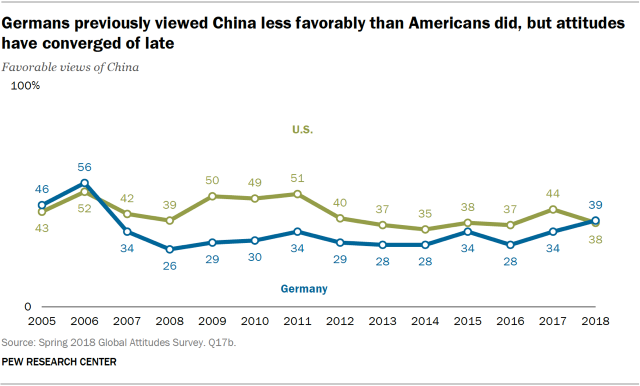

**Question**

What's the color of graph with 56 as the highest value?

Query key          : cq_0
Gold (correct)     : Blue
Unevolved (seed)   : Blue.   ← WRONG
Evolved            : Blue   ← CORRECT
Reloaded `evolved` for the benchmark cell below.


In [ ]:
import os
from pathlib import Path
import gc
import sys
import torch
from IPython.display import display, Markdown, Image as IPyImage
from evaluate_chartqa import find_contrastive_chartqa_sample

MAX_CONTRASTIVE_SCAN = int(os.environ.get("MAX_CONTRASTIVE_SCAN", "120"))


def _vram_detach(mod_name: str) -> None:
    if mod_name in sys.modules:
        m = sys.modules.pop(mod_name)
        for attr in ("_model", "_processor"):
            if hasattr(m, attr):
                setattr(m, attr, None)
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


_vram_detach("evolved_chartqa_colab")
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

print(f"Scanning up to {MAX_CONTRASTIVE_SCAN} seed failures on ChartQA …")
seed_v = load_module("_contrast_seed", PROJECT_ROOT / "seed_instruct.py")
evo_v = load_module("_contrast_evo", PROJECT_ROOT / "evolved_chartqa.py")
pair = find_contrastive_chartqa_sample(seed_v, evo_v, max_failure_checks=MAX_CONTRASTIVE_SCAN)
_vram_detach("_contrast_seed")
_vram_detach("_contrast_evo")

if pair is None:
    display(Markdown("### No contrastive example found"))
    print(
        f"No chart in the first {MAX_CONTRASTIVE_SCAN} seed failures where "
        "unevolved is wrong AND evolved is correct."
    )
    print("Try increasing MAX_CONTRASTIVE_SCAN or re-running evolution.")
else:
    CONTRASTIVE_SAMPLE = pair
    p = Path(pair["image_path"])
    if not p.is_file():
        raise FileNotFoundError(p)
    display(Markdown("## Contrastive chart from ChartQA"))
    display(Markdown("*Unevolved (seed) is wrong; evolved matches gold.*"))
    display(IPyImage(filename=str(p)))
    q = pair["question"]
    display(Markdown("**Question**"))
    display(Markdown((q[:2000] + "…") if len(q) > 2000 else q))
    print("Query key          :", pair["key"])
    print("Gold (correct)     :", pair["gold"])
    print("Unevolved (seed)   :", pair["seed_response"], "  ← WRONG")
    print("Evolved            :", pair["evolved_response"], "  ← CORRECT")

evolved = load_module("evolved_chartqa_colab", PROJECT_ROOT / "evolved_chartqa.py")
print("Reloaded `evolved` for the benchmark cell below.")



In [ ]:
from evaluate_chartqa import evaluate

print("=== BENCHMARK — after AlphaEvolve ===")
bench_after = evaluate(evolved, return_details=False)
for k in ("desc_accuracy", "num_desc_evaluated", "num_errors", "total_time", "avg_time_per_query"):
    print(f"  {k}: {bench_after[k]}")
print("\n=== SUMMARY (ChartQA / SmolVLM2-2.2B-Instruct: seed → evolved) ===")
print(f"Accuracy: {bench_before['desc_accuracy']:.4f} → {bench_after['desc_accuracy']:.4f}")
print("\n=== SAME-SAMPLE BEFORE / AFTER ===")
try:
    q = SAMPLE["question"]
    print("Question (trim):", (q[:240] + "…") if len(q) > 240 else q)
    print("Gold     :", SAMPLE["gold"])
    print("Seed pred:", before_pred)
    print("Evolved  :", after_pred)
except NameError:
    print("(Re-run the two EXAMPLE cells so `before_pred` and `after_pred` exist.)")


=== BENCHMARK — after AlphaEvolve ===


Loading weights:   0%|          | 0/657 [00:00<?, ?it/s]

  desc_accuracy: 0.4114583333333333
  num_desc_evaluated: 192
  num_errors: 0
  total_time: 98.92385220527649
  avg_time_per_query: 0.5152283969024817

=== SUMMARY (ChartQA / SmolVLM2-2.2B-Instruct: seed → evolved) ===
Accuracy: 0.1146 → 0.4115

=== SAME-SAMPLE BEFORE / AFTER ===
Question (trim): What's the color of graph with 56 as the highest value?
Gold     : Blue
Seed pred:  Blue.
Evolved  : Blue
